<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project4_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 4: Are Motor-Cortex Spike Counts Poisson?**

**Question.** Are the spike counts of mouse motor-cortex neurons as variable as a Poisson process predicts, and how much of the extra variability does movement explain?

**Minimum result.** Fano factors (50 ms counts) and CVs for the 20 highest-rate neurons of session 10, each compared with Poisson simulations of the same rate.

**Lessons to revisit.** 12 (Poisson rate models, gradient descent), 17 (CV, Fano factor, law of total variance), 18 (Poisson).

**Data.** `steinmetz_s10_hench_mop.npz` (and `steinmetz_s28_radnitz_mop.npz` for the stretch goal). Steinmetz et al. (2019), *Nature* 576:266–273; subsets of the Neuromatch Academy release; the original data are released under CC0.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `S10` | (342, 447, 250) | (trial, neuron, 10 ms bin): spike counts; spike times are known only to 10 ms |
| `C` | (342 × 50, 447) | counts in 50 ms bins, rows trial by trial |
| `speed` | (342 × 50,) | wheel speed in the same bins, thousand steps/s |

C: (17100, 447)  mean counts of the top 20 neurons: [3.39 1.86 1.71 1.69 1.39 1.35 1.32 1.25 1.24 1.15 1.07 1.07 1.05 1.03
 1.02 0.97 0.95 0.9  0.89 0.89]


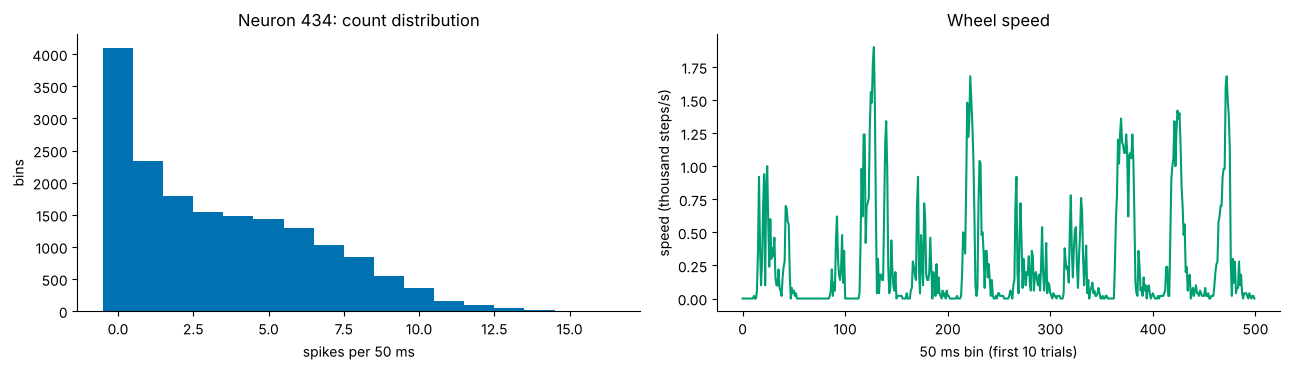

In [2]:
d = load('steinmetz_s10_hench_mop.npz')
S10 = d['spikes']
n_tr, n_neu, _ = S10.shape
C = S10.reshape(n_tr, n_neu, 50, 5).sum(axis=3).transpose(0, 2, 1).reshape(-1, n_neu)        # (17100, 447) spikes per 50 ms
speed = np.abs(d['wheel'].reshape(n_tr, 50, 5).sum(axis=2) / 0.05).reshape(-1) / 1000         # (17100,) thousand steps/s
top20 = np.argsort(-C.mean(axis=0))[:20]
print("C:", C.shape, " mean counts of the top 20 neurons:", np.round(C[:, top20].mean(axis=0), 2))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
j = top20[0]
axes[0].hist(C[:, j], bins=np.arange(-0.5, C[:, j].max() + 1.5), color=PALETTE[0])
axes[0].set_xlabel('spikes per 50 ms'); axes[0].set_ylabel('bins'); axes[0].set_title(f'Neuron {j}: count distribution')
axes[1].plot(speed[:500], color=PALETTE[2]); axes[1].set_xlabel('50 ms bin (first 10 trials)'); axes[1].set_ylabel('speed (thousand steps/s)'); axes[1].set_title('Wheel speed')
plt.tight_layout(); plt.show()

### Worked first step: one neuron's Fano factor against a Poisson null

In [3]:
c = C[:, j]
ff = c.var(ddof=1) / c.mean()
null = [(lambda s: s.var(ddof=1) / s.mean())(rng.poisson(c.mean(), size=c.size)) for _ in range(200)]
print(f"neuron {j}: mean {c.mean():.2f} spikes/50 ms, Fano factor {ff:.2f};  Poisson with the same mean: 95% of FFs in {np.round(np.percentile(null, [2.5, 97.5]), 3)}")

neuron 434: mean 3.39 spikes/50 ms, Fano factor 2.88;  Poisson with the same mean: 95% of FFs in [0.982 1.022]


In [4]:
# TODO 1 -- For each of the 20 neurons in top20 store, in arrays of shape (20,):
#   ff20 -- Fano factor of the 50 ms counts;   ff_hi -- 97.5th percentile of 200 Poisson-null FFs with the same mean
#   cv20 -- CV of the interspike intervals within trials, spikes placed at their 10 ms bin (Lesson 17)
# Plot ff20 and ff_hi against the mean count.
ff20 = ff_hi = cv20 = None

In [5]:
if todo(ff20, ff_hi, cv20):
    print('TODO 1 not done yet.')
else:
    assert np.shape(ff20) == np.shape(cv20) == (20,)
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- A speed-dependent Poisson model (Lesson 12). For each neuron, fit lambda = exp(a + b * speed) (expected count per
# 50 ms) by minimising the Poisson negative log-likelihood sum(lambda - c * log(lambda)): gradient descent converges slowly
# here, so use Newton's method (Lesson 11) and check that the gradient is close to zero at the end. Then store
# ff_resid (20,): the variance of (c - lambda) divided by the mean of lambda, a Fano factor after the model.
ff_resid = None

In [7]:
if todo(ff_resid):
    print('TODO 2 not done yet.')
else:
    assert np.shape(ff_resid) == (20,) and np.all(ff_resid > 0)
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Law of total variance with two states: moving (speed > 0) and still. For each neuron store
# within (20,) = E[Var(count | state)] and between (20,) = Var(E[count | state]), weighting each state by its share of bins.
within = between = None

In [9]:
if todo(within, between):
    print('TODO 3 not done yet.')
else:
    jj = top20[0]; assert abs(within[0] + between[0] - C[:, jj].var()) < 1e-8, "the two parts should add up to the total variance"
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- Fano factors depend on the window: report the window, and try 10 ms and 500 ms as well.
- Spike times are binned at 10 ms: intervals shorter than 10 ms are not resolved, which affects the CV.
- Stretch: repeat in `steinmetz_s28_radnitz_mop.npz`.